### Q3.1

In [47]:
import hashlib

# 1. Get the username part of your email
username = "ritama.sanyal"

# 2. Generate the seed using the provided formula
your_seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)

print(f"Your personalized random seed is: {your_seed}")

Your personalized random seed is: 284869898


In [48]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load the dataset
df = pd.read_csv('Clustering_dataset_q2.csv')

# --- Preprocessing Steps ---

# 1. Select relevant features
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].copy() # Use .copy() to avoid SettingWithCopyWarning

# 2. Check for missing data
print("Missing values per column:")
print(X.isnull().sum())
# If there were missing values, you could fill them with the mean:
X = X.fillna(X.mean())

# 3. Scale the data
# GMM assumes Gaussian distributions, which is affected by scale.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Check for NaN or inf values in the scaled data
if np.isnan(X_scaled).any() or np.isinf(X_scaled).any():
    print('\nWarning: X_scaled contains NaN or inf values. Replacing them with column means.')
    # Replace NaN or inf with column means
    col_means = np.nanmean(np.where(np.isinf(X_scaled), np.nan, X_scaled), axis=0)
    inds = np.where(np.isnan(X_scaled) | np.isinf(X_scaled))
    X_scaled[inds] = np.take(col_means, inds[1])
else:
    print('\nX_scaled is clean (no NaN or inf values).')


print("\nData shape after preprocessing:", X_scaled.shape)

Missing values per column:
Annual Income (k$)        6
Spending Score (1-100)    6
dtype: int64

X_scaled is clean (no NaN or inf values).

Data shape after preprocessing: (200, 2)


In [49]:
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

class GMM:
    """
    A Gaussian Mixture Model class implemented from scratch.
    """
    # Add a regularization parameter to __init__
    def __init__(self, k, max_iter=100, tol=1e-4, reg_cov=1e-6):
        """
        Initializes the GMM.

        Parameters:
        k (int): The number of Gaussian components (clusters).
        max_iter (int): The maximum number of iterations for the EM algorithm.
        tol (float): The tolerance for convergence of the log-likelihood.
        reg_cov (float): Regularization added to the diagonal of covariance matrices.
        """
        self.k = k
        self.max_iter = max_iter
        self.tol = tol
        self.reg_cov = reg_cov # Store regularization value
        self.weights = None
        self.means = None
        self.covs = None
        self.likelihood_history = []
        self.responsibilities = None

    def _initialize_params(self, X):
        """Initializes weights, means, and covariance matrices."""
        n_samples, n_features = X.shape

        self.weights = np.full(self.k, 1/self.k)
        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.means = X[random_indices]
        self.covs = np.array([np.eye(n_features) for _ in range(self.k)])

    def _e_step(self, X):
        """Performs the Expectation (E) step of the EM algorithm."""
        likelihoods = np.zeros((X.shape[0], self.k))
        for i in range(self.k):
            # Add a small value to the diagonal of covs for stability in the first pass
            cov_reg = self.covs[i] + self.reg_cov * np.eye(self.covs[i].shape[0])
            distribution = multivariate_normal(mean=self.means[i], cov=cov_reg)
            likelihoods[:, i] = distribution.pdf(X)
        
        weighted_likelihoods = likelihoods * self.weights
        sum_of_likelihoods = np.sum(weighted_likelihoods, axis=1, keepdims=True)
        
        # Add a small epsilon to avoid division by zero if a point has 0 likelihood for all clusters
        self.responsibilities = weighted_likelihoods / (sum_of_likelihoods + 1e-9)

    def _m_step(self, X):
        """Performs the Maximization (M) step of the EM algorithm."""
        n_samples, n_features = X.shape
        
        Nk = np.sum(self.responsibilities, axis=0)

        # 1. Update weights
        self.weights = Nk / n_samples

        # 2. Update means
        self.means = (self.responsibilities.T @ X) / (Nk[:, np.newaxis] + 1e-9)

        # 3. Update covariances
        for i in range(self.k):
            diff = X - self.means[i]
            cov_i = (self.responsibilities[:, i, np.newaxis] * diff).T @ diff
            
            # --- THIS IS THE FIX ---
            # Divide by Nk and add the regularization term to the diagonal
            self.covs[i] = (cov_i / (Nk[i] + 1e-9)) + self.reg_cov * np.eye(n_features)


    def _calculate_log_likelihood(self, X):
        """Calculates the log-likelihood of the data."""
        likelihoods = np.zeros((X.shape[0], self.k))
        for i in range(self.k):
            distribution = multivariate_normal(self.means[i], self.covs[i])
            likelihoods[:, i] = distribution.pdf(X)
            
        weighted_likelihoods = likelihoods @ self.weights
        log_likelihood = np.sum(np.log(weighted_likelihoods + 1e-9)) 
        return log_likelihood

    def fit(self, X):
        """
        Fits the GMM to the dataset using the EM algorithm.
        """
        self._initialize_params(X)
        
        for i in range(self.max_iter):
            # E-Step and M-Step
            try:
                self._e_step(X)
                self._m_step(X)
                log_likelihood = self._calculate_log_likelihood(X)
            except np.linalg.LinAlgError:
                print(f"Singular matrix error at iteration {i}. Stopping.")
                break

            self.likelihood_history.append(log_likelihood)
            
            # Check for convergence
            if i > 0 and abs(log_likelihood - self.likelihood_history[-2]) < self.tol:
                print(f"Converged at iteration {i+1}")
                break
        print("Fitting complete.")

    def getMembership(self):
        """
        Returns the membership values (responsibilities) for each sample.
        """
        if self.responsibilities is None:
            raise ValueError("Model has not been fitted yet. Call fit() first.")
        return self.responsibilities

    def getLikelihood(self):
        """
        Returns the final log-likelihood of the dataset.
        """
        if not self.likelihood_history:
            raise ValueError("Model has not been fitted yet. Call fit() first.")
        return self.likelihood_history[-1]

    def drawLikelihood(self, username="ritama.sanyal"):
        """
        Draws the plot of log-likelihood vs. iterations.
        """
        if not self.likelihood_history:
            print("Likelihood history is empty. Call fit() first.")
            return
            
        plt.figure(figsize=(10, 6))
        plt.text(0.95, 0.95, "ritama.sanyal", ha='right', va='top', 
         transform=plt.gca().transAxes, fontsize=10, color='gray', alpha=0.7)
        plt.plot(self.likelihood_history, marker='o')
        plt.title(f'Log-Likelihood vs. Iterations')
        plt.xlabel('Iteration')
        plt.ylabel('Log-Likelihood')
        plt.grid(True)
        plt.show()

Converged at iteration 66
Fitting complete.

Final Log-Likelihood: -470.8255
Shape of membership matrix: (200, 5)
First 5 membership probabilities:
 [[2.76428132e-06 3.38222507e-07 9.99778204e-01 1.04691042e-16
  2.18623361e-04]
 [9.76864712e-01 4.13287874e-17 3.79263759e-09 1.54849952e-13
  2.31352682e-02]
 [3.72927027e-16 2.24172710e-03 2.11682646e-09 2.89858704e-56
  9.97758241e-01]
 [1.22695946e-01 3.85768340e-21 9.85410076e-22 8.77304033e-01
  4.41250067e-17]
 [4.80415600e-06 2.97584549e-07 9.99576368e-01 1.05714824e-14
  4.18470767e-04]]


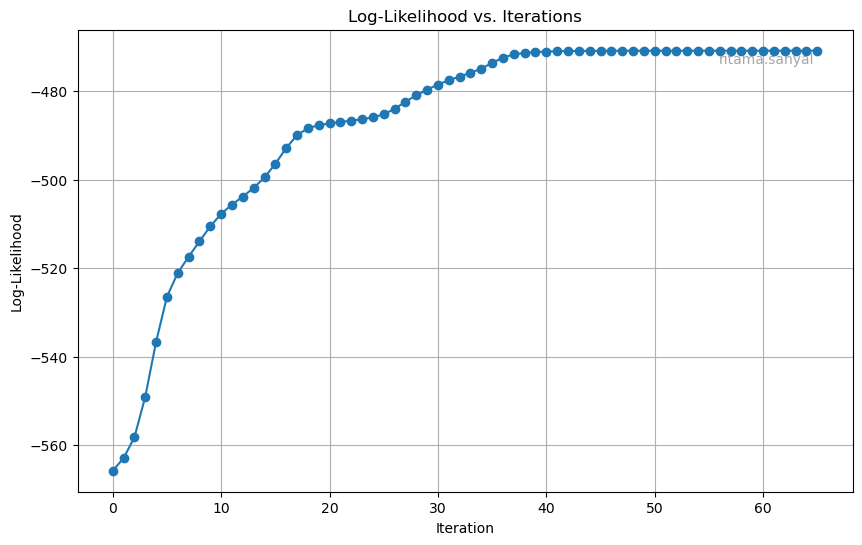

In [50]:
# --- Using the GMM Class ---

# 1. Instantiate the GMM with k=5 clusters
gmm = GMM(k=5, max_iter=150)

# 2. Fit the model to the scaled data
gmm.fit(X_scaled)

# 3. Get the final log-likelihood
final_likelihood = gmm.getLikelihood()
print(f"\nFinal Log-Likelihood: {final_likelihood:.4f}")

# 4. Get the membership probabilities
memberships = gmm.getMembership()
print(f"Shape of membership matrix: {memberships.shape}")
print("First 5 membership probabilities:\n", memberships[:5])

# 5. Plot the likelihood vs. iterations
gmm.drawLikelihood()

### Q3.2

In [51]:
from sklearn.metrics import silhouette_score
import time

# Define the range of k to test
k_range = range(2, 20)
bic_scores = []
silhouette_scores = []

n_samples, n_features = X_scaled.shape

print("Calculating scores for different values of k...")
for k in k_range:
    start_time = time.time()
    
    # 1. Fit the GMM model
    gmm = GMM(k=k, max_iter=100)
    gmm.fit(X_scaled)
    
    # 2. Calculate BIC
    log_likelihood = gmm.getLikelihood()
    n_params_cov = k * n_features * (n_features + 1) / 2
    n_params_mean = k * n_features
    n_params_weights = k - 1
    n_params = n_params_cov + n_params_mean + n_params_weights
    
    bic = np.log(n_samples) * n_params - 2 * log_likelihood
    bic_scores.append(bic)
    
    # 3. Calculate Silhouette Score
    # Get cluster assignments from the highest membership probability
    labels = np.argmax(gmm.getMembership(), axis=1)
    silhouette = silhouette_score(X_scaled, labels)
    silhouette_scores.append(silhouette)
    
    end_time = time.time()
    print(f"k={k}: BIC={bic:.2f}, Silhouette={silhouette:.4f} (took {end_time - start_time:.2f}s)")

Calculating scores for different values of k...
Converged at iteration 25
Fitting complete.
k=2: BIC=1120.95, Silhouette=0.0908 (took 0.02s)
Converged at iteration 93
Fitting complete.
k=3: BIC=1122.89, Silhouette=0.3521 (took 0.06s)
Converged at iteration 67
Fitting complete.
k=4: BIC=1099.24, Silhouette=0.1774 (took 0.06s)
Converged at iteration 67
Fitting complete.
k=4: BIC=1099.24, Silhouette=0.1774 (took 0.06s)
Fitting complete.
k=5: BIC=1069.99, Silhouette=0.5358 (took 0.10s)
Converged at iteration 78
Fitting complete.
k=6: BIC=1111.96, Silhouette=0.1838 (took 0.10s)
Fitting complete.
k=5: BIC=1069.99, Silhouette=0.5358 (took 0.10s)
Converged at iteration 78
Fitting complete.
k=6: BIC=1111.96, Silhouette=0.1838 (took 0.10s)
Converged at iteration 70
Fitting complete.
k=7: BIC=1118.16, Silhouette=0.1822 (took 0.10s)
Fitting complete.
k=8: BIC=1100.20, Silhouette=0.3289 (took 0.17s)
Converged at iteration 70
Fitting complete.
k=7: BIC=1118.16, Silhouette=0.1822 (took 0.10s)
Fitting

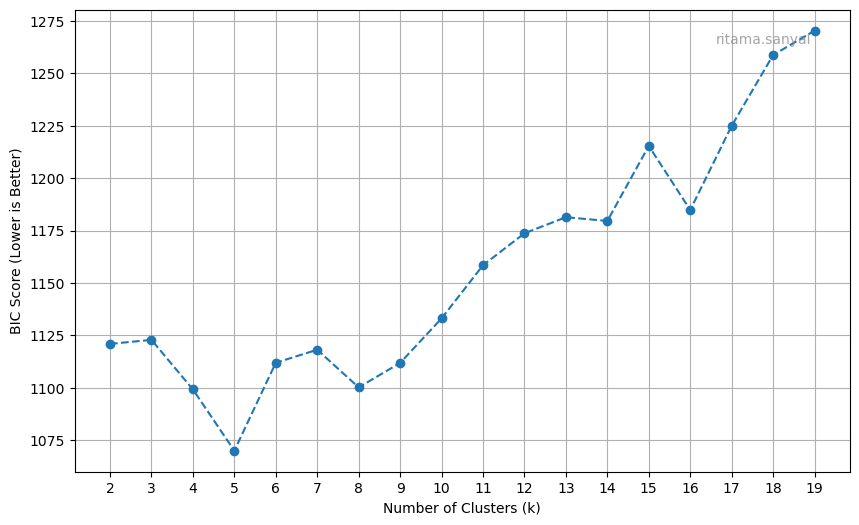

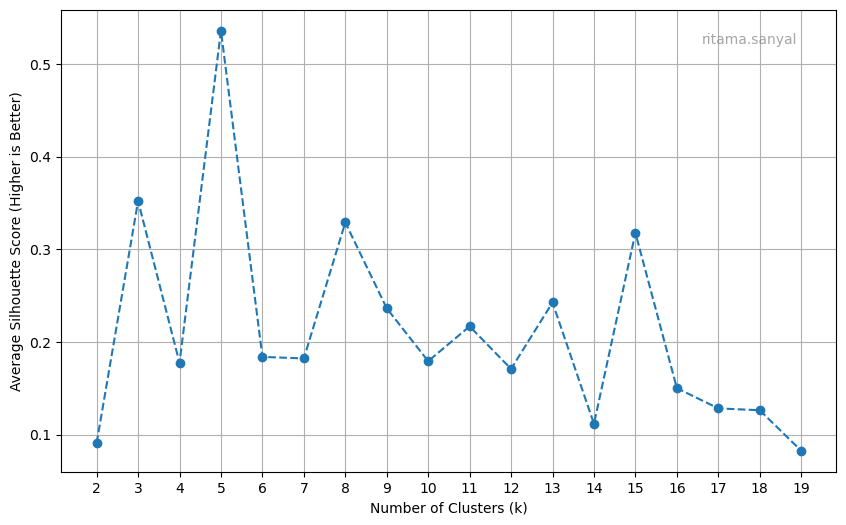

In [52]:
def plot_scores(k_range, scores, title, xlabel, ylabel, username="ritama.sanyal"):
    """Helper function to plot scores vs. number of clusters."""
    plt.figure(figsize=(10, 6))
    plt.plot(k_range, scores, marker='o', linestyle='--')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.text(0.95, 0.95, "ritama.sanyal", ha='right', va='top', 
         transform=plt.gca().transAxes, fontsize=10, color='gray', alpha=0.7)
    plt.xticks(k_range)
    plt.grid(True)
    plt.show()

# Plot BIC scores
plot_scores(k_range, bic_scores, 
            'BIC vs. Number of Clusters', 
            'Number of Clusters (k)', 
            'BIC Score (Lower is Better)')

# Plot Silhouette scores
plot_scores(k_range, silhouette_scores, 
            'Silhouette Score vs. Number of Clusters', 
            'Number of Clusters (k)', 
            'Average Silhouette Score (Higher is Better)')

# Cluster Number Analysis

---

## BIC Method Analysis

The first graph plots the **Bayesian Information Criterion (BIC)** score against the number of clusters (`k`).  
For the BIC metric, a **lower score indicates a better model**, as it balances model fit with complexity.

From the plot:
- The BIC score reaches its distinct **minimum value at k = 5**.  
- After this point, the score consistently trends upwards, indicating that adding more clusters makes the model overly complex without a sufficient improvement in fit.

**Conclusion**: The BIC method clearly suggests that the optimal number of clusters is **5**.

---

## Silhouette Method Analysis

The second graph shows the **Average Silhouette Score**, which measures how well-separated the clusters are.  
For this metric, a **higher score is better**.

From the plot:
- A sharp and prominent peak occurs at **k = 5**, achieving the highest score (over 0.5).  
- Other local peaks exist (e.g., at k = 3, k = 8, k = 15), but they are all significantly lower.  

The strong peak at k = 5 indicates that this clustering configuration results in dense and well-defined clusters.

**Conclusion**: The Silhouette method also strongly points to an optimal number of clusters of **5**.

---

## Overall Summary

Unlike the previous results, both evaluation methods now converge on the same conclusion:

- The **BIC score is minimized at k = 5**.  
- The **Silhouette score is maximized at k = 5**.  

This agreement provides a strong and confident indication that **5 is the optimal number of clusters** for this dataset.


https://g.co/gemini/share/bab9a8d49c64